In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

from data_loading import data_loading, files
df = data_loading(files['final_df'])

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 513801 entries, 0 to 513800
Data columns (total 51 columns):
 #   Column                                             Non-Null Count   Dtype         
---  ------                                             --------------   -----         
 0   collision_index                                    513801 non-null  object        
 1   collision_severity                                 513801 non-null  int64         
 2   date                                               513801 non-null  datetime64[ns]
 3   day_of_week                                        513801 non-null  int64         
 4   time                                               513801 non-null  object        
 5   latitude                                           513748 non-null  float64       
 6   longitude                                          513748 non-null  float64       
 7   urban_or_rural_area                                513793 non-null  float64       
 8   spee

#**Exploratary Data Anyalysis**

In [3]:
df.columns

Index(['collision_index', 'collision_severity', 'date', 'day_of_week', 'time',
       'latitude', 'longitude', 'urban_or_rural_area', 'speed_limit',
       'road_type', 'light_conditions', 'weather_conditions',
       'road_surface_conditions', 'special_conditions_at_site',
       'carriageway_hazards', 'junction_detail', 'junction_control',
       'trunk_road_flag', 'number_of_vehicles', 'number_of_casualties',
       'did_police_officer_attend_scene_of_accident',
       'collision_severity_label', 'day_of_week_label',
       'urban_or_rural_area_label', 'road_type_label',
       'light_conditions_label', 'weather_conditions_label',
       'road_surface_conditions_label', 'special_conditions_at_site_label',
       'carriageway_hazards_label', 'junction_detail_label',
       'junction_control_label', 'trunk_road_flag_label',
       'did_police_officer_attend_scene_of_accident_label', 'min_driver_age',
       'max_driver_age', 'max_vehicle_age', 'max_engine_cc',
       'male_driver_shar

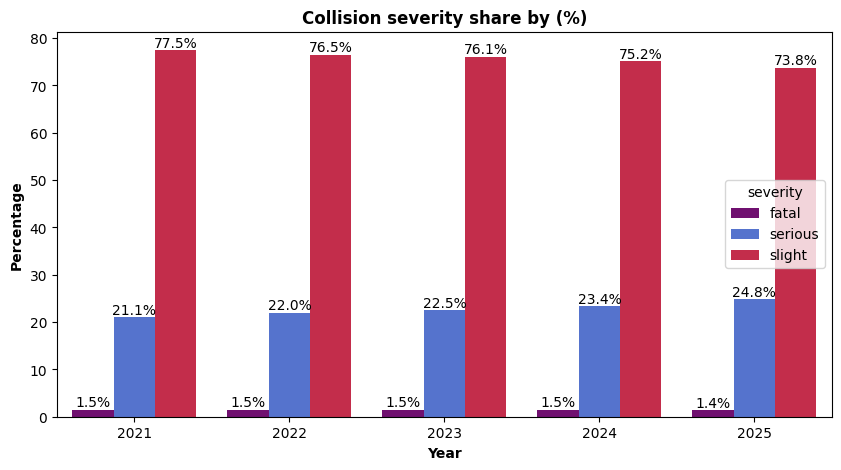

In [4]:

# Severity per years

pct = (
    df.groupby('year')['collision_severity_label']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename('percent')
    .reset_index()
)

# plot
fig, ax = plt.subplots(figsize=(10,5))
colors={
    'fatal': 'purple',
    'serious': 'royalblue',
    'slight': 'crimson'
}
sns.barplot(
    data=pct,
    x='year',
    y='percent',
    hue='collision_severity_label',
    hue_order=['fatal', 'serious', 'slight'],
    palette=colors,
    ax=ax
)


bars = [0, 1, 2]
for bar in bars:
  ax.bar_label(ax.containers[bar], fmt='%1.1f%%')

ax.set_title("Collision severity share by (%)", fontweight='bold')
ax.set_xlabel("Year", fontweight='semibold'),
ax.set_ylabel("Percentage", fontweight='semibold')
plt.legend(title='severity')
plt.show()

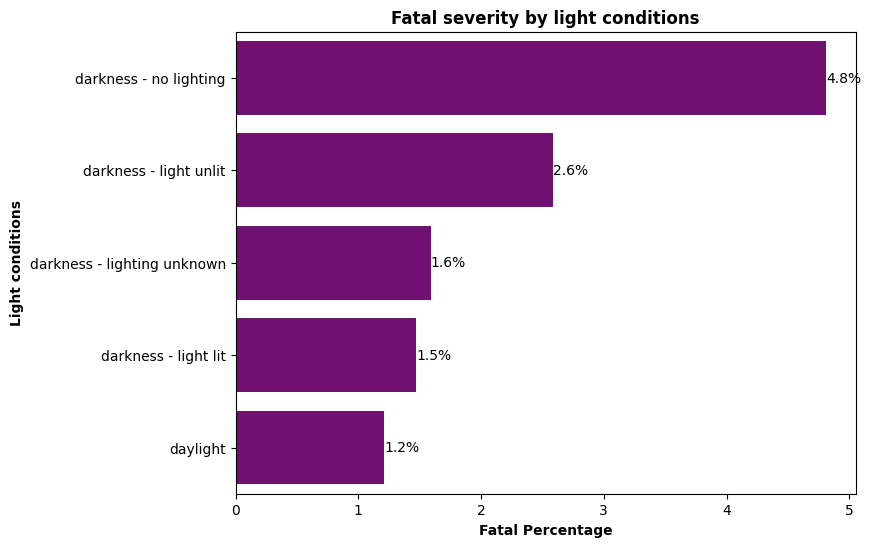

In [5]:
# Darkness vs Daylight:


df['fatal'] = df['collision_severity'].eq(1)

rate = (
    df.groupby('light_conditions_label', observed=True)['fatal']
    .agg(['mean', 'size'])
    .rename(columns={'mean': 'fatal_pct', 'size': 'total'})
)

rate['fatal_pct'] = (rate['fatal_pct'] * 100).round(2)
rate = rate.sort_values('fatal_pct', ascending=False).reset_index()

plot_rate = rate[rate['light_conditions_label'] != 'data missing or out of range']

fig, ax = plt.subplots(figsize=(8,6))
sns.barplot(
    data=plot_rate,
    x='fatal_pct',
    y='light_conditions_label',
    color='purple',
    ax=ax
)

ax.set_title("Fatal severity by light conditions", fontweight='bold')
ax.set_xlabel("Fatal Percentage", fontweight='semibold')
ax.set_ylabel("Light conditions", fontweight='semibold')
ax.bar_label(ax.containers[0], fmt='%1.1f%%')

plt.show()



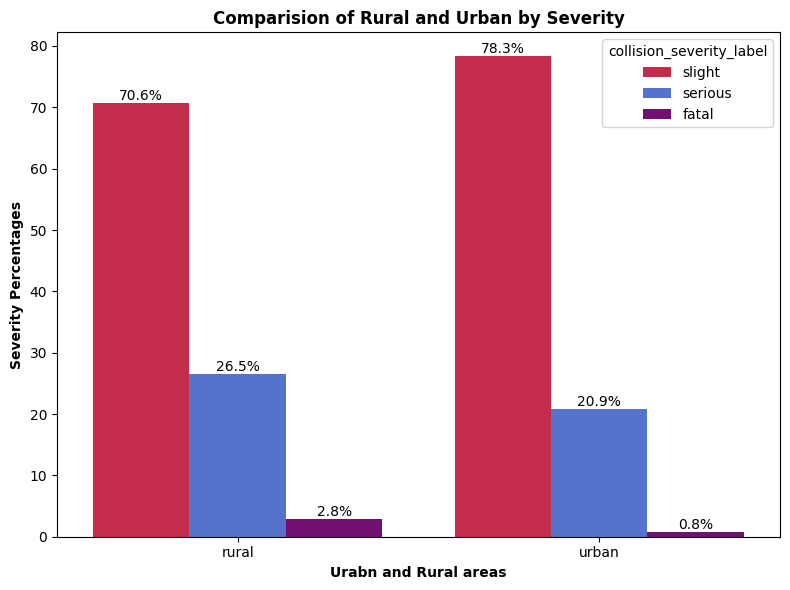

In [6]:
# Severity of Rural and Urban areas:

area_pct = (
    df.groupby('urban_or_rural_area_label')['collision_severity_label']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename('percent')
    .reset_index()
)

rural_sev_plot = area_pct[area_pct['urban_or_rural_area_label'].isin(['urban', 'rural'])]
fig, ax = plt.subplots(figsize=(8,6))
colors={
    'fatal': 'purple',
    'serious': 'royalblue',
    'slight': 'crimson'
}
sns.barplot(
    data=rural_sev_plot,
    x='urban_or_rural_area_label',
    y='percent',
    hue='collision_severity_label',
    palette=colors,
    ax=ax
)

ax.set_title("Comparision of Rural and Urban by Severity", fontweight='bold')
ax.set_xlabel("Urabn and Rural areas", fontweight='semibold')
ax.set_ylabel("Severity Percentages", fontweight='semibold')

bars = [0, 1, 2]
for bar in bars:
  ax.bar_label(ax.containers[bar], fmt='%1.1f%%')
plt.tight_layout()
plt.show()

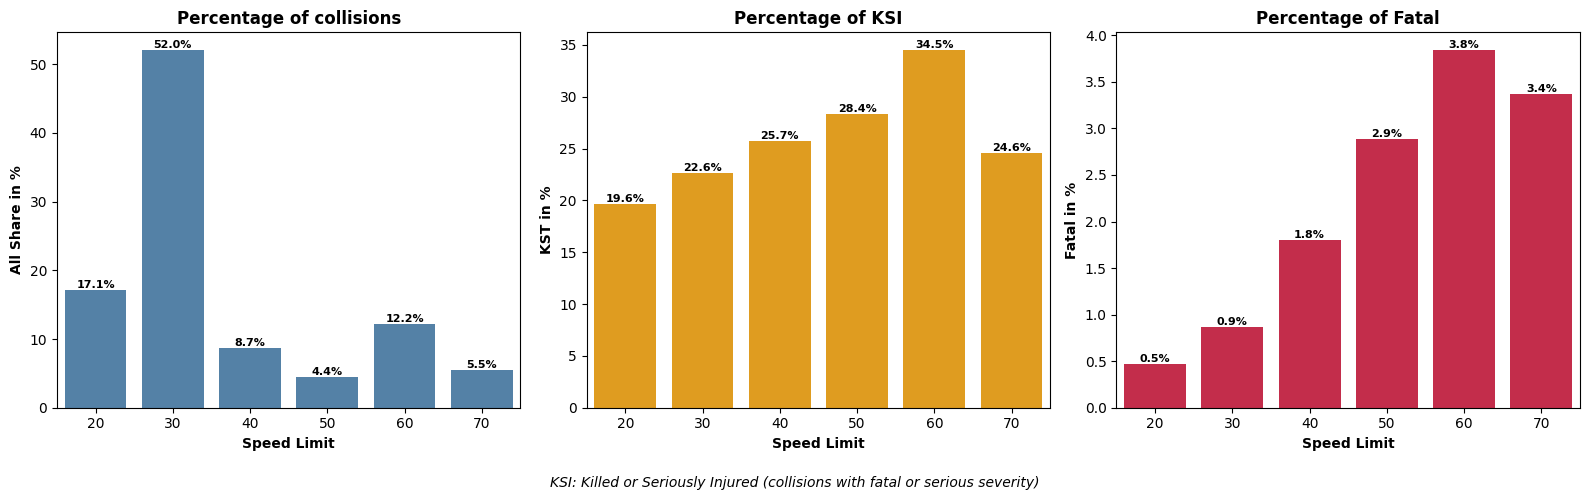

In [7]:
# df['speed_limit'].value_counts()

sp = df.dropna(subset=['speed_limit']).copy()
sp['speed_limit'] = sp['speed_limit'].astype('int')
sp['fatal'] = sp['collision_severity'].eq(1)
sp['ksi'] = sp['collision_severity'].isin([1, 2])

sp_data = (
    sp.groupby('speed_limit')
    .agg(
        total=('collision_index', 'size'),
        fatal_pct=('fatal', 'mean'),
        ksi_pct=('ksi', 'mean')
    )
    .reset_index()
)
sp_data['share_of_all_pct'] = ((sp_data['total']/sp_data['total'].sum()) * 100).round(2)
sp_data['fatal_pct'] = (sp_data['fatal_pct'] * 100).round(2)
sp_data['ksi_pct'] = (sp_data['ksi_pct'] * 100).round(2)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(
    data=sp_data,
    x='speed_limit',
    y='share_of_all_pct',
    color='steelblue',
    ax=axes[0]
)

sns.barplot(
    data=sp_data,
    x='speed_limit',
    y='ksi_pct',
    color='orange',
    ax=axes[1]
)

sns.barplot(
    data=sp_data,
    x='speed_limit',
    y='fatal_pct',
    color='crimson',
    ax=axes[2]
)

# bar label
points = [0, 1, 2]
for point in points:
  axes[point].bar_label(axes[point].containers[0], fmt="%1.1f%%",fontsize=8, fontweight='semibold')

# titles
axes[0].set_title("Percentage of collisions", fontweight='bold')
axes[1].set_title("Percentage of KSI", fontweight='bold')
axes[2].set_title("Percentage of Fatal", fontweight='bold')

# x labels
for point in points:
  axes[point].set_xlabel("Speed Limit", fontweight='semibold')

# y labels
axes[0].set_ylabel("All Share in %", fontweight='semibold')
axes[1].set_ylabel("KST in %", fontweight='semibold')
axes[2].set_ylabel("Fatal in %", fontweight='semibold')
fig.supxlabel("KSI: Killed or Seriously Injured (collisions with fatal or serious severity)",
              fontsize=10, style='italic')
plt.tight_layout()
plt.show()
plt.show()
plt.show()

In [22]:
geo = df.dropna(subset=['latitude', 'longitude'])

ksi_geo = geo[geo['collision_severity'].isin([1,2])]

grid = (
    geo
    .assign(
        lat_grid=ksi_geo['latitude'].round(3),
        long_grid=ksi_geo['longitude'].round(3)
    )
    .groupby(['lat_grid', 'long_grid'])
    .size()
    .rename('ksi_count')
    .reset_index()
)

fig = px.density_map(
    grid,
    lat='lat_grid',
    lon='long_grid',
    z='ksi_count',
    radius=10,
    zoom=5,
    center={'lat': 55.3781, "lon": -3.4360},
    color_continuous_scale='YlOrRd',
    title='Fatal + serious (KSI) collisions density'
)
fig.show(renderers='png')


         latitude  longitude  collision_severity collision_severity_label
0       54.698400  -1.247000                   2                  serious
1       54.563870  -1.191470                   2                  serious
2       54.606000  -1.083900                   3                   slight
3       54.551570  -1.375990                   3                   slight
4       54.562280  -1.315960                   2                  serious
...           ...        ...                 ...                      ...
513796  51.483380  -0.053770                   3                   slight
513797  51.513199  -0.045541                   3                   slight
513798  51.512994  -0.016219                   2                  serious
513799  51.506802  -0.004240                   3                   slight
513800  51.473794  -0.148673                   3                   slight

[513801 rows x 4 columns]
